# 04 — Hypothesis Testing: Game Ratings

Notebook pemula ini membandingkan rating dua kelompok platform. Data sintetis, sehingga hasil hanya untuk latihan statistik.

In [13]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
games = pd.read_csv(PROJECT_DIR / 'data' / 'games_eda.csv')
games.groupby('platform')['rating'].agg(['count','mean','std']).round(2)

,count,mean,std
platform,,,
Mobile,17,7.15,1.37
PC,14,7.11,1.56
PlayStation,19,7.03,1.32
Switch,15,6.79,0.79
Xbox,15,7.30,1.37


## 1. Rumuskan hipotesis
Contoh pertanyaan: apakah rata-rata rating game di PC berbeda dari rating game di Switch?

- **H0 (hipotesis nol):** rata-rata rating PC dan Switch sama.
- **H1 (hipotesis alternatif):** rata-rata rating PC dan Switch berbeda.

Kita gunakan uji t Welch untuk latihan. Interpretasikan p-value bersama konteks dan ukuran sampel.

In [14]:
pc = games.loc[games['platform'] == 'PC', 'rating'].dropna()
switch = games.loc[games['platform'] == 'Switch', 'rating'].dropna()
print('Jumlah game PC:', len(pc))
print('Jumlah game Switch:', len(switch))
print('Rata-rata PC:', round(pc.mean(), 2))
print('Rata-rata Switch:', round(switch.mean(), 2))

Jumlah game PC: 14
Jumlah game Switch: 15
Rata-rata PC: 7.11
Rata-rata Switch: 6.79


## 2. Jalankan uji statistik
Jika SciPy belum tersedia, pasang dengan `python -m pip install scipy` setelah memilih versi Python yang kompatibel.

In [15]:
try:
    from scipy.stats import ttest_ind
    result = ttest_ind(pc, switch, equal_var=False, alternative='two-sided')
    print('t-statistic:', round(result.statistic, 3))
    print('p-value:', round(result.pvalue, 4))
    alpha = 0.05
    if result.pvalue < alpha:
        print('Keputusan: tolak H0 pada taraf signifikansi 5%.')
    else:
        print('Keputusan: belum cukup bukti untuk menolak H0 pada taraf signifikansi 5%.')
except ImportError:
    print('SciPy belum terpasang. Pasang dengan: python -m pip install scipy')

t-statistic: 0.693
p-value: 0.4967
Keputusan: belum cukup bukti untuk menolak H0 pada taraf signifikansi 5%.


## 3. Visualisasi

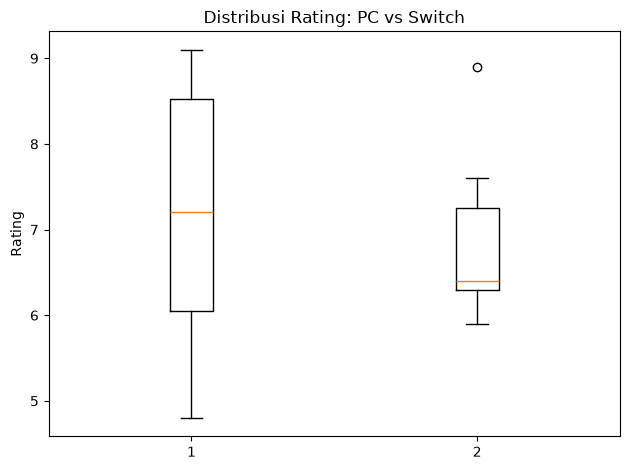

In [16]:
plt.boxplot([pc, switch], label=['PC','Switch'])
plt.title('Distribusi Rating: PC vs Switch')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()

## Interpretasi
Tulis jawabanmu:
1. Berapa rata-rata rating tiap kelompok?
2. Apa arti p-value dalam konteks uji ini?
3. Apakah hasil ini membuktikan platform menyebabkan rating lebih tinggi? (Tidak; data ini observasional dan sintetis.)
4. Apa keterbatasan ukuran sampel dan data sintetis?